# lowpoly: геометрия и CatBoost

Проверяем, помогают ли геометрические признаки находить недостаточную детализацию. Намеренно простой примитив сам по себе не равен `lowpoly`. Используем прежнее разбиение: 6259 / 1361 / 1344. Internal test здесь не оцениваем.

У больших мешей берём четыре непрерывных участка граней (в сумме до 12 000), чтобы сохранить реальные пары соседних граней. Это приближение, поэтому в таблице признаков сохраняются число просмотренных граней и статус. Файлы больше 150 МБ пропускаем. Неопределённые признаки остаются `NaN`: CatBoost умеет с ними работать.

## 1. Данные и то же разбиение

In [1]:
%pip install -q catboost iterative-stratification scipy tqdm

from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from catboost import CatBoostClassifier, Pool
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data/train.csv').is_file())
WORK = ROOT / 'labels/lowpoly'
ART = WORK / 'artifacts'
MODELS = WORK / 'models'
ART.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)
sys.path.insert(0, str(WORK))
from geometry_features import NEW_FEATURES, extract_one

SEED = 42
np.random.seed(SEED)
train = pd.read_csv(ROOT / 'data/train.csv')
targets = train.columns.drop('item_id').tolist()
assert train.item_id.is_unique
split = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=.15, random_state=42)
train_val_index, test_index = next(split.split(train, train[targets]))
train_val = train.iloc[train_val_index].reset_index(drop=True)
test_df = train.iloc[test_index].reset_index(drop=True)
split = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=.1765, random_state=43)
train_index, val_index = next(split.split(train_val, train_val[targets]))
train_df = train_val.iloc[train_index].reset_index(drop=True)
val_df = train_val.iloc[val_index].reset_index(drop=True)
assert (len(train_df), len(val_df), len(test_df)) == (6259, 1361, 1344)
assert not (set(train_df.item_id) & set(val_df.item_id))
assert not (set(train_df.item_id) & set(test_df.item_id))
assert not (set(val_df.item_id) & set(test_df.item_id))
print('Train:', len(train_df), 'Validation:', len(val_df), 'Internal test:', len(test_df))
print('lowpoly positives:', int(train_df.lowpoly.sum()), int(val_df.lowpoly.sum()))

Note: you may need to restart the kernel to use updated packages.


C:\Users\gasre\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train: 6259 Validation: 1361 Internal test: 1344
lowpoly positives: 775 166


## 2. Исходные 44 признака и существующий baseline

In [2]:
archive = ROOT / 'archive'
config = json.loads((archive / 'artifacts/catboost_features_config.json').read_text(encoding='utf-8'))
base_columns = config['feature_columns']
assert config['target_columns'] == targets and len(base_columns) == 44
assert not set(base_columns) & set(NEW_FEATURES), 'Новые названия дублируют старые'
base = pd.read_csv(archive / 'artifacts/train_mesh_features_relative.csv').set_index('item_id')
assert base.index.is_unique and set(train.item_id) == set(base.index)
assert np.isfinite(base[base_columns].to_numpy()).all()
print('Исходные признаки:', base_columns)
print('Новые признаки:', NEW_FEATURES)

def metrics(y, probabilities, threshold):
    prediction = probabilities >= threshold
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {'Precision': precision_score(y, prediction, zero_division=0),
            'Recall': recall_score(y, prediction, zero_division=0),
            'F1': f1_score(y, prediction, zero_division=0),
            'AP': average_precision_score(y, probabilities),
            'ROC_AUC': roc_auc_score(y, probabilities),
            'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn),
            'Threshold': float(threshold)}

y_train = train_df.lowpoly.to_numpy()
y_val = val_df.lowpoly.to_numpy()
old = CatBoostClassifier()
old.load_model(str(archive / 'models/catboost_features/lowpoly.cbm'))
assert old.feature_names_ == base_columns
old_prob = old.predict_proba(base.loc[val_df.item_id, base_columns])[:, 1]
old_threshold = config['thresholds'][targets.index('lowpoly')]
old_catboost = metrics(y_val, old_prob, old_threshold)
print('Сохранённый CatBoost:', pd.Series(old_catboost).round(4).to_string())
print('Fusion F1 0.5464 взят из archive/cnn_mesh_fusion.ipynb, ниже проверяем его по checkpoint.')

Исходные признаки:

 ['vertices_count', 'faces_count', 'faces_per_vertex', 'size_x', 'size_y', 'size_z', 'size_min', 'size_middle', 'size_max', 'min_to_max', 'middle_to_max', 'bbox_volume', 'bbox_diagonal', 'std_x', 'std_y', 'std_z', 'radius_mean', 'radius_std', 'radius_max', 'edge_mean', 'edge_std', 'edge_max', 'face_area_mean', 'face_area_std', 'face_area_max', 'surface_area', 'degenerate_faces_ratio', 'std_x_relative', 'std_y_relative', 'std_z_relative', 'radius_mean_relative', 'radius_std_relative', 'radius_max_relative', 'edge_mean_relative', 'edge_std_relative', 'edge_max_relative', 'face_area_mean_relative', 'face_area_std_relative', 'face_area_max_relative', 'surface_area_relative', 'radius_variation', 'edge_variation', 'face_area_variation', 'bbox_fill']
Новые признаки: ['edge_min_relative', 'edge_p10_relative', 'edge_p50_relative', 'edge_p90_relative', 'edge_p95_relative', 'edge_long_share', 'area_p10_relative', 'area_p50_relative', 'area_p90_relative', 'area_p95_relative', 'area_max_to_median',

In [3]:
# Воспроизводим прежние 0.5464 по сохранённой ResNet18 и CatBoost.
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18

reference_path = ART / 'existing_fusion_validation.csv'
if reference_path.is_file():
    reference = pd.read_csv(reference_path)
    assert reference.item_id.tolist() == val_df.item_id.tolist()
    reference_prob = reference.probability.to_numpy()
else:
    checkpoint = torch.load(archive / 'models/resnet/best_resnet18_improved.pth',
                            map_location='cpu', weights_only=True)
    assert checkpoint['target_columns'] == targets
    resnet = resnet18(weights=None)
    resnet.fc = nn.Linear(resnet.fc.in_features, len(targets))
    resnet.load_state_dict(checkpoint['model_state_dict'])
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    resnet = resnet.to(device).eval()
    transform = transforms.Compose([
        transforms.Resize((224, 336)), transforms.ToTensor(),
        transforms.Normalize([.485, .456, .406], [.229, .224, .225])
    ])
    class Renders(Dataset):
        def __len__(self):
            return len(val_df)
        def __getitem__(self, index):
            item_id = val_df.item_id.iloc[index]
            with Image.open(ROOT / 'data/train' / f'{item_id}.png') as image:
                return transform(image.convert('RGB'))
    loader = DataLoader(Renders(), batch_size=32, shuffle=False, num_workers=0)
    outputs = []
    with torch.inference_mode():
        for images in tqdm(loader, desc='Старая ResNet18'):
            outputs.append(torch.sigmoid(resnet(images.to(device)))[:, targets.index('lowpoly')].cpu().numpy())
    resnet_prob = np.concatenate(outputs)
    fusion_config = json.loads((archive / 'artifacts/resnet_catboost_features_config.json').read_text(encoding='utf-8'))
    reference_prob = fusion_config['resnet_weight'] * resnet_prob + fusion_config['catboost_weight'] * old_prob
    pd.DataFrame({'item_id': val_df.item_id, 'probability': reference_prob}).to_csv(reference_path, index=False)
    del resnet
fusion_config = json.loads((archive / 'artifacts/resnet_catboost_features_config.json').read_text(encoding='utf-8'))
old_fusion = metrics(y_val, reference_prob, fusion_config['thresholds']['lowpoly'])
print('Сохранённая связка:', pd.Series(old_fusion).round(4).to_string())
assert abs(old_fusion['F1'] - .5464) < .0001

Сохранённая связка: Precision       0.4882
Recall          0.6205
F1              0.5464
AP              0.5604
ROC_AUC         0.8776
TP            103.0000
TN           1087.0000
FP            108.0000
FN             63.0000
Threshold       0.4600


## 3. Проверка нескольких мешей

In [4]:
train_dir = ROOT / 'data/train'
checks = pd.concat([
    train_df.loc[train_df.lowpoly.eq(1), 'item_id'].sample(3, random_state=42),
    train_df.loc[train_df.lowpoly.eq(0), 'item_id'].sample(3, random_state=42),
    base['faces_count'].nsmallest(2).index.to_series(),
    base['faces_count'].nlargest(2).index.to_series()
]).drop_duplicates()
check_rows = [extract_one(item_id, train_dir) for item_id in checks]
check_table = pd.DataFrame(check_rows)
# На небольших полных мешах проверяем число связных частей.
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
def component_count(item_id, row):
    if row['status'] not in ('ok', 'zero_area') or row['original_faces'] > 12000:
        return np.nan
    with np.load(train_dir / f'{item_id}.npz', allow_pickle=False) as mesh:
        vertices, faces = mesh['vertices'], mesh['faces']
    if len(faces) > 12000 or len(vertices) > 100000 or len(faces) == 0:
        return np.nan
    if faces.ndim != 2 or faces.shape[1] != 3 or (faces < 0).any() or (faces >= len(vertices)).any():
        return np.nan
    edges_a = np.concatenate([faces[:, 0], faces[:, 1], faces[:, 2]])
    edges_b = np.concatenate([faces[:, 1], faces[:, 2], faces[:, 0]])
    graph = coo_matrix((np.ones(len(edges_a)), (edges_a, edges_b)),
                       shape=(len(vertices), len(vertices)))
    _, labels = connected_components(graph, directed=False)
    return len(np.unique(labels[np.unique(faces)]))
check_table['components'] = [component_count(item_id, row)
                             for item_id, row in zip(checks, check_rows)]
display(check_table[['item_id', 'status', 'original_faces', 'sampled_faces',
                     'invalid_faces', 'degenerate_faces', 'duplicate_vertex_share',
                     'components', 'interior_edges', 'boundary_edge_share', 'nonmanifold_edge_share',
                     'dihedral_p90', 'pca_curvature_p90']].round(4))
assert not np.isinf(check_table[NEW_FEATURES].to_numpy(dtype=float)).any()

,item_id,status,original_faces,sampled_faces,invalid_faces,degenerate_faces,duplicate_vertex_share,components,interior_edges,boundary_edge_share,nonmanifold_edge_share,dihedral_p90,pca_curvature_p90
0,92cfb530-ab8c-4056-bc7f-4c51a76c604e,ok,184.0,184,0,0,0.0000,1.0,276,0.0000,0.0000,61.1490,0.0451
1,e9f5ce0f-c6af-4941-a909-447d81258c7b,ok,3710.0,3710,0,0,0.0000,1.0,5545,0.0000,0.0018,69.7394,0.0975
2,71746176-940c-4150-8206-8b9a7c8b348e,sampled,144558.0,12000,0,0,0.0141,NaN,14604,0.3174,0.0000,11.6424,0.0854
3,b2afc2b8-8dcb-40b8-8954-c73b1ea7da1d,sampled,248376.0,12000,0,0,0.0000,NaN,3464,0.8935,0.0000,45.1379,0.1497
4,017c4c1c-e426-4854-b57b-9f19cff79ea8,ok,9814.0,9814,0,9,0.0000,1.0,14677,0.0004,0.0010,80.9077,0.1601
5,00811de2-8795-43b1-813d-3f5f458a926b,sampled,750018.0,12000,0,0,0.0067,NaN,13953,0.3671,0.0000,58.1732,0.1157
6,e50f6e85-59d3-4449-a1cc-f2dbceed36ea,ok,4.0,4,0,0,0.0000,2.0,2,0.8000,0.0000,0.0000,NaN
7,6bfa4228-62cd-434b-b97c-53ec6292fb6f,ok,8.0,8,0,0,0.0000,2.0,6,0.6667,0.0000,40.2739,NaN
8,6fab7518-6dbc-4f50-a3ef-4d9aafee6ca0,oversize_file,NaN,0,0,0,NaN,NaN,0,NaN,NaN,NaN,NaN
9,58174dd2-7c8a-46eb-98c4-312d774a7968,sampled,16416788.0,12000,0,10,0.0007,NaN,15771,0.2192,0.0000,29.9303,0.2139


## 4. Извлечение новых признаков для train и validation

In [5]:
cache_path = ART / 'geometry_features.csv'
rows = pd.read_csv(cache_path).to_dict('records') if cache_path.is_file() else []
done = {row['item_id'] for row in rows}
needed = pd.concat([train_df.item_id, val_df.item_id], ignore_index=True)
missing = [item_id for item_id in needed if item_id not in done]
print('Всего:', len(needed), 'осталось:', len(missing))
from concurrent.futures import ThreadPoolExecutor
try:
    with ThreadPoolExecutor(max_workers=3) as pool:
        extracted = pool.map(lambda item_id: extract_one(item_id, train_dir), missing)
        for count, row in enumerate(tqdm(extracted, total=len(missing), desc='Mesh features'), 1):
            rows.append(row)
            if count % 100 == 0:
                pd.DataFrame(rows).to_csv(cache_path, index=False)
finally:
    pd.DataFrame(rows).to_csv(cache_path, index=False)
geometry = pd.DataFrame(rows).set_index('item_id')
geometry = geometry.loc[needed]
assert len(geometry) == 7620 and geometry.index.is_unique
assert not np.isinf(geometry[NEW_FEATURES].to_numpy(dtype=float)).any()
display(geometry.status.value_counts().rename('Объектов'))
display(geometry[['invalid_faces', 'degenerate_faces', 'interior_edges']].describe().round(1))

Всего: 7620 осталось: 0


Mesh features: 0it [00:00, ?it/s]

Mesh features: 0it [00:00, ?it/s]

status
sampled          5759
ok               1860
oversize_file       1
Name: Объектов, dtype: int64

,invalid_faces,degenerate_faces,interior_edges
count,7620.0,7620.0,7620.0
mean,0.0,27.1,12027.7
std,0.0,265.4,5068.5
min,0.0,0.0,0.0
25%,0.0,0.0,8833.0
50%,0.0,0.0,14082.5
75%,0.0,0.0,15943.0
max,0.0,9327.0,18000.0


## 5. E1–E4: одинаковый CatBoost и подбор порога

In [6]:
features = base[base_columns].join(geometry[NEW_FEATURES], how='inner', validate='one_to_one')
assert len(features) == 7620
assert features.index.is_unique
assert not np.isinf(features.to_numpy(dtype=float)).any()
threshold_grid = np.arange(.05, .96, .01)
parameters = config['parameters'].copy()
assert parameters.get('auto_class_weights') is None
results, models = [], {}
probabilities = val_df[['item_id', 'lowpoly']].copy()
experiment_columns = {
    'E1_existing44': base_columns,
    'E2_new_geometry': NEW_FEATURES,
    'E3_combined': base_columns + NEW_FEATURES,
}

def fit_experiment(name, columns):
    model = CatBoostClassifier(**parameters)
    X_train = features.loc[train_df.item_id, columns]
    X_val = features.loc[val_df.item_id, columns]
    model.fit(X_train, y_train, eval_set=(X_val, y_val),
              early_stopping_rounds=50, verbose=False)
    p = model.predict_proba(X_val)[:, 1]
    f1_values = [f1_score(y_val, p >= t) for t in threshold_grid]
    threshold = float(threshold_grid[np.argmax(f1_values)])
    result = {'Experiment': name, 'Features': len(columns),
              **metrics(y_val, p, threshold), 'Trees': model.tree_count_}
    results.append(result)
    models[name] = model
    probabilities[name] = p
    model.save_model(str(MODELS / f'{name}.cbm'))
    pd.DataFrame(results).to_csv(ART / 'metrics.csv', index=False)
    probabilities.to_csv(ART / 'validation_probabilities.csv', index=False)
    (ART / 'experiment_config.json').write_text(json.dumps({
        'seed': SEED, 'parameters': parameters,
        'experiments': {r['Experiment']: {'columns': experiment_columns[r['Experiment']],
                                        'threshold': r['Threshold'], 'trees': r['Trees']}
                        for r in results}}, indent=2), encoding='utf-8')
    print(name, '| F1:', round(result['F1'], 4), '| AP:', round(result['AP'], 4),
          '| trees:', result['Trees'], flush=True)

for name, columns in experiment_columns.items():
    fit_experiment(name, columns)

importance_e3 = pd.Series(models['E3_combined'].feature_importances_,
                          index=experiment_columns['E3_combined']).sort_values(ascending=False)
experiment_columns['E4_selected'] = importance_e3.head(20).index.tolist()
fit_experiment('E4_selected', experiment_columns['E4_selected'])
# Проверяем вклад двух групп, на которые указывает importance.
ablation_groups = {
    'A_no_curvature': [x for x in NEW_FEATURES
                       if x.startswith(('curvature', 'pca_curvature', 'normal_variation'))],
    'A_no_dihedral': [x for x in NEW_FEATURES if x.startswith('dihedral')],
}
for name, removed in ablation_groups.items():
    experiment_columns[name] = [x for x in experiment_columns['E3_combined'] if x not in removed]
    fit_experiment(name, experiment_columns[name])
results_table = pd.DataFrame(results)
display(results_table.round(4))

E1_existing44 | F1: 0.5519 | AP: 0.5802 | trees: 254


E2_new_geometry | F1: 0.5329 | AP: 0.5915 | trees: 345


E3_combined | F1: 0.5879 | AP: 0.6324 | trees: 375


E4_selected | F1: 0.5778 | AP: 0.5634 | trees: 185


A_no_curvature | F1: 0.5984 | AP: 0.6335 | trees: 413


A_no_dihedral | F1: 0.5617 | AP: 0.6176 | trees: 300


,Experiment,Features,Precision,Recall,F1,AP,ROC_AUC,TP,TN,FP,FN,Threshold,Trees
0,E1_existing44,44,0.5986,0.5120,0.5519,0.5802,0.8790,85,1138,57,81,0.32,254
1,E2_new_geometry,44,0.6260,0.4639,0.5329,0.5915,0.8826,77,1149,46,89,0.36,345
2,E3_combined,88,0.5404,0.6446,0.5879,0.6324,0.8993,107,1104,91,59,0.24,375
3,E4_selected,20,0.5361,0.6265,0.5778,0.5634,0.8893,104,1105,90,62,0.25,185
4,A_no_curvature,78,0.5415,0.6687,0.5984,0.6335,0.9005,111,1101,94,55,0.23,413
5,A_no_dihedral,76,0.5759,0.5482,0.5617,0.6176,0.8943,91,1128,67,75,0.29,300


## 6. Сравнение с прежней моделью

In [7]:
core_results = results_table[results_table.Experiment.str.startswith('E')].copy()
comparison = pd.concat([
    pd.DataFrame([{'Experiment': 'Existing best fusion', 'Features': 'ResNet18 + CatBoost44', **old_fusion}]),
    pd.DataFrame([{'Experiment': 'Existing CatBoost44', 'Features': 44, **old_catboost}]),
    core_results
], ignore_index=True)
display(comparison[['Experiment', 'Features', 'Precision', 'Recall', 'F1', 'AP',
                    'ROC_AUC', 'FP', 'FN', 'Threshold']].round(4))
display(results_table[results_table.Experiment.str.startswith('A')][
    ['Experiment', 'Features', 'Precision', 'Recall', 'F1', 'AP', 'FP', 'FN', 'Threshold']].round(4))
print('E5 simplification: не запускали из-за больших мешей; метрик нет.')
best_name = results_table.loc[results_table.F1.idxmax(), 'Experiment']
best_model = models[best_name]
best_columns = experiment_columns[best_name]
best_row = results_table.set_index('Experiment').loc[best_name]
best_prediction = probabilities[best_name].to_numpy() >= best_row.Threshold
print('Лучший CatBoost:', best_name, '| F1:', round(best_row.F1, 4),
      '| разница с fusion:', round(best_row.F1 - old_fusion['F1'], 4))

,Experiment,Features,Precision,Recall,F1,AP,ROC_AUC,FP,FN,Threshold
0,Existing best fusion,ResNet18 + CatBoost44,0.4882,0.6205,0.5464,0.5604,0.8776,108,63,0.46
1,Existing CatBoost44,44,0.5986,0.5120,0.5519,0.5802,0.8790,57,81,0.32
2,E1_existing44,44,0.5986,0.5120,0.5519,0.5802,0.8790,57,81,0.32
3,E2_new_geometry,44,0.6260,0.4639,0.5329,0.5915,0.8826,46,89,0.36
4,E3_combined,88,0.5404,0.6446,0.5879,0.6324,0.8993,91,59,0.24
5,E4_selected,20,0.5361,0.6265,0.5778,0.5634,0.8893,90,62,0.25


,Experiment,Features,Precision,Recall,F1,AP,FP,FN,Threshold
4,A_no_curvature,78,0.5415,0.6687,0.5984,0.6335,94,55,0.23
5,A_no_dihedral,76,0.5759,0.5482,0.5617,0.6176,67,75,0.29


E5 simplification: не запускали из-за больших мешей; метрик нет.
Лучший CatBoost: A_no_curvature | F1: 0.5984 | разница с fusion: 0.052


## 7. Важность признаков и SHAP

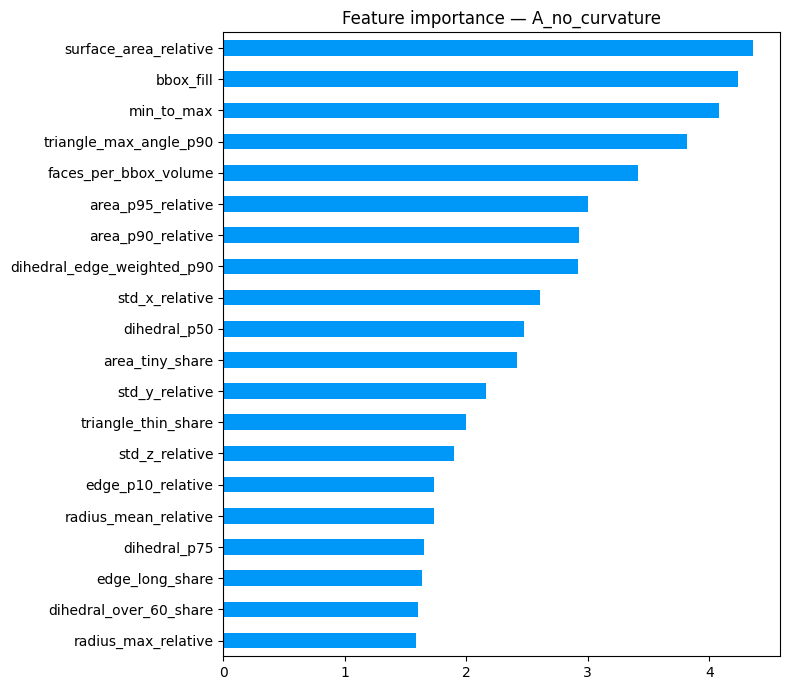

Новых признаков в топ-20: ['triangle_max_angle_p90', 'faces_per_bbox_volume', 'area_p95_relative', 'area_p90_relative', 'dihedral_edge_weighted_p90', 'dihedral_p50', 'area_tiny_share', 'triangle_thin_share', 'edge_p10_relative', 'dihedral_p75', 'edge_long_share', 'dihedral_over_60_share']


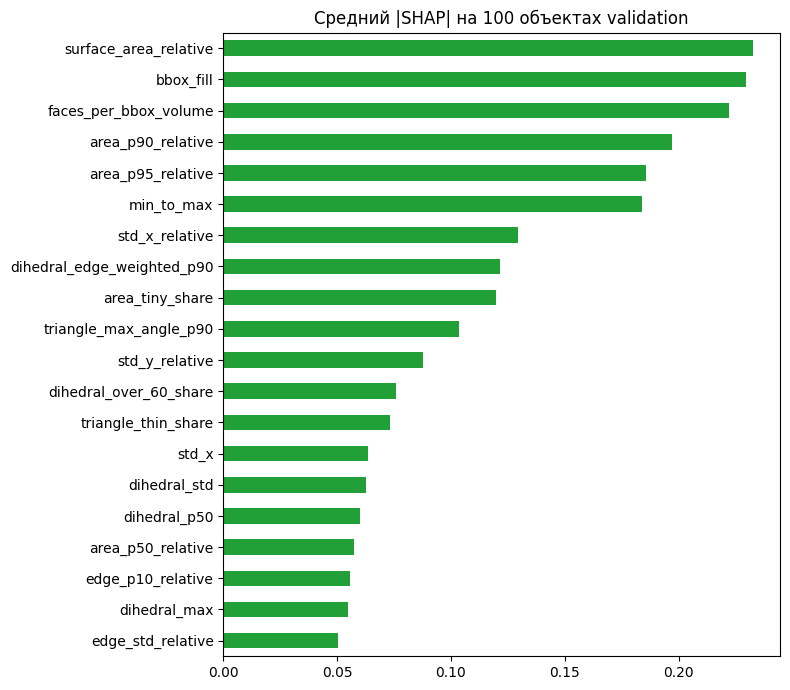

Коррелирующие признаки могут делить важность. SHAP не доказывает причинность.


In [8]:
importance = pd.Series(best_model.feature_importances_, index=best_columns).sort_values(ascending=False)
top = importance.head(20).sort_values()
ax = top.plot.barh(figsize=(8, 7), color='#0098F8')
ax.set_title('Feature importance — ' + best_name)
plt.tight_layout(); plt.show()
print('Новых признаков в топ-20:', [name for name in importance.head(20).index if name in NEW_FEATURES])

shap_rows = val_df.sample(min(100, len(val_df)), random_state=42)
shap_data = Pool(features.loc[shap_rows.item_id, best_columns])
shap_values = best_model.get_feature_importance(shap_data, type='ShapValues')[:, :-1]
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=best_columns).sort_values(ascending=False)
ax = shap_importance.head(20).sort_values().plot.barh(figsize=(8, 7), color='#21A038')
ax.set_title('Средний |SHAP| на 100 объектах validation')
plt.tight_layout(); plt.show()
print('Коррелирующие признаки могут делить важность. SHAP не доказывает причинность.')

## 8. Ошибки по группам и изображения

lowpoly + simple | объектов: 13 | FN: 4
lowpoly + noisy | объектов: 12 | FN: 8
lowpoly + artifacts | объектов: 10 | FN: 3
lowpoly without these | объектов: 136 | FN: 42
FP | всего: 94


,item_id,lowpoly,simple,noisy,artifacts,probability,faces_count,dihedral_p90,pca_curvature_p90,edge_p90_relative,triangle_aspect_p90
510,60c00b2d-2090-4f90-b060-77c14c66cfd9,0,0,1,1,0.8657,1849,32.0139,0.1750,0.0356,2.4965
410,4be5c961-8ab2-472d-a3da-339bd8e7f718,0,1,0,0,0.7286,598,89.1701,0.2142,0.1754,17.2679
898,aa15d5f6-d746-40ae-86f9-58849e7448bb,0,0,0,0,0.6979,9212,44.4184,0.2144,0.0216,9.8382
853,a0a60028-f981-45f8-acd4-19802ffbb45c,0,0,0,0,0.6588,5096,24.2926,0.1253,0.0154,12.3911


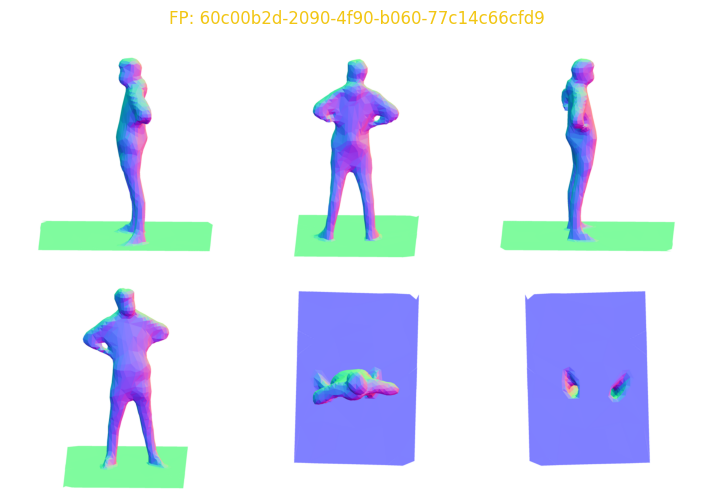

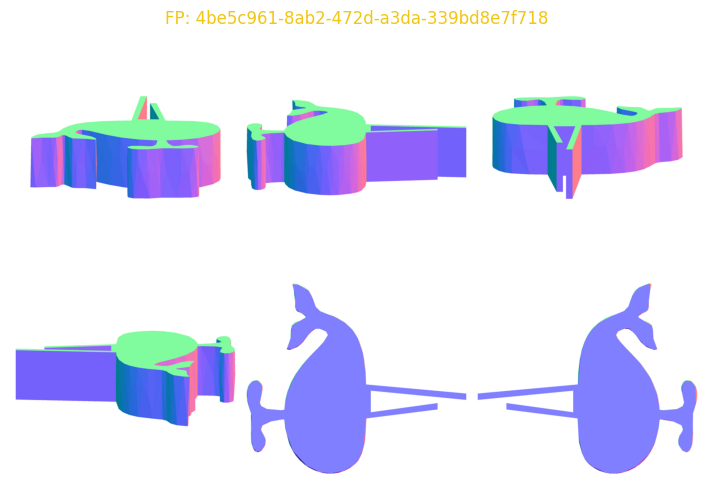

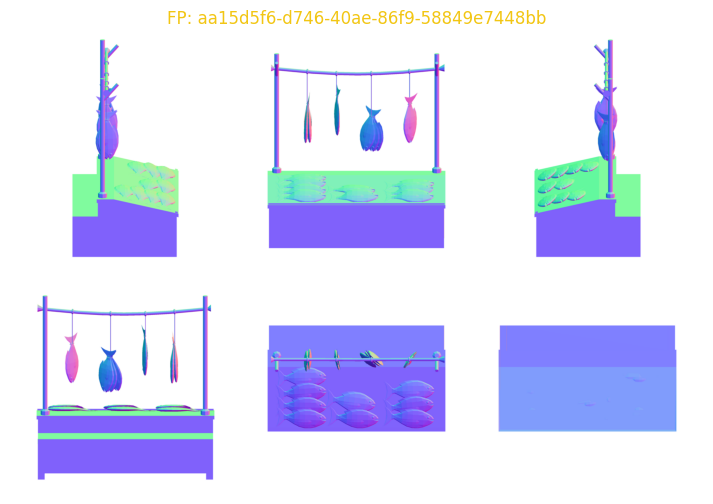

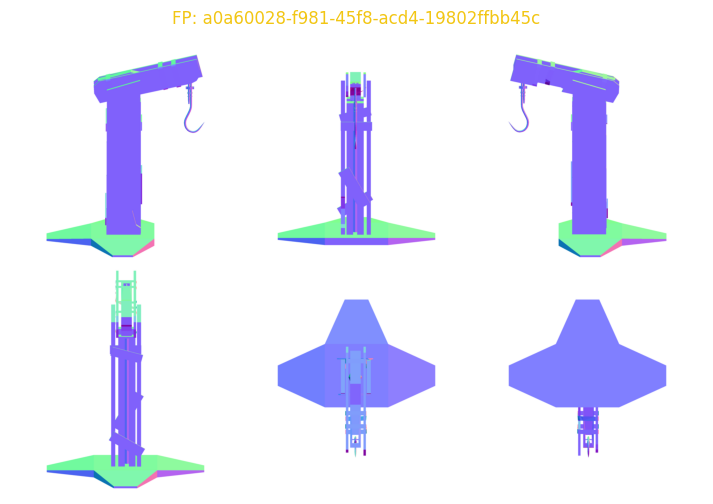

FN | всего: 55


,item_id,lowpoly,simple,noisy,artifacts,probability,faces_count,dihedral_p90,pca_curvature_p90,edge_p90_relative,triangle_aspect_p90
1275,f0d6be10-327d-49ee-bcbb-4a1048f50018,1,1,1,0,0.0077,322688,18.8688,0.0958,0.0028,2.3787
837,9de3b5d1-8951-48ee-b749-3b574e519003,1,0,1,0,0.0198,200000,22.1000,0.0968,0.0044,2.9472
273,34e9d7a9-c38f-4095-a5f0-42bb68a9d965,1,0,0,0,0.0201,156990,12.9581,0.1423,0.0046,3.0082
245,2f1acff9-3afa-4a77-8403-2c2f4318a914,1,0,1,1,0.0281,647774,7.9923,0.1557,0.0024,1.7018


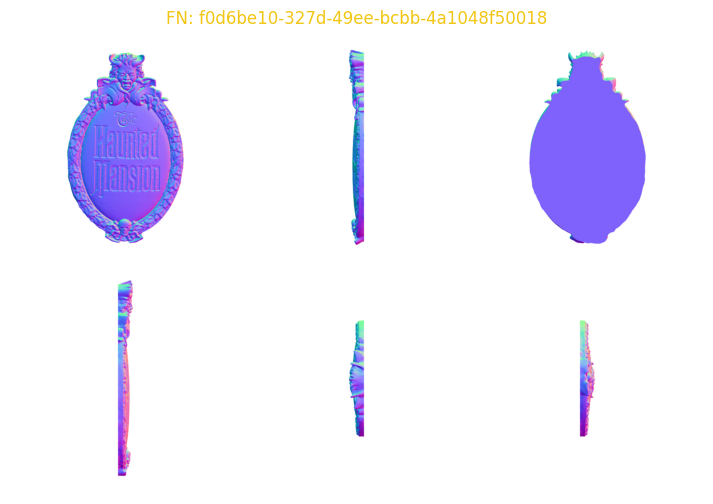

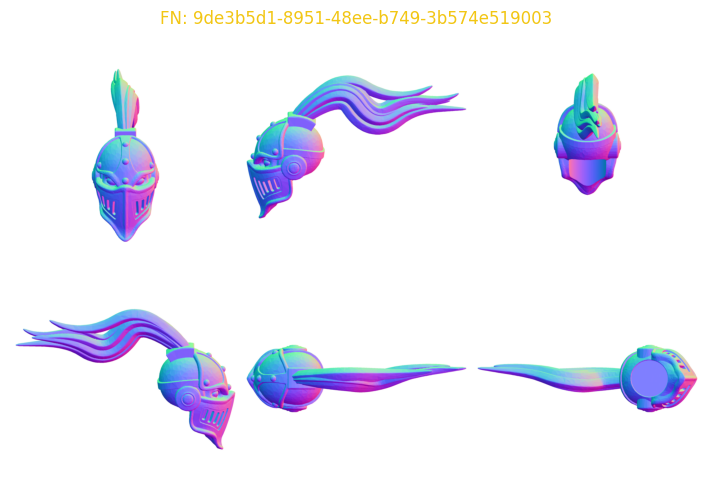

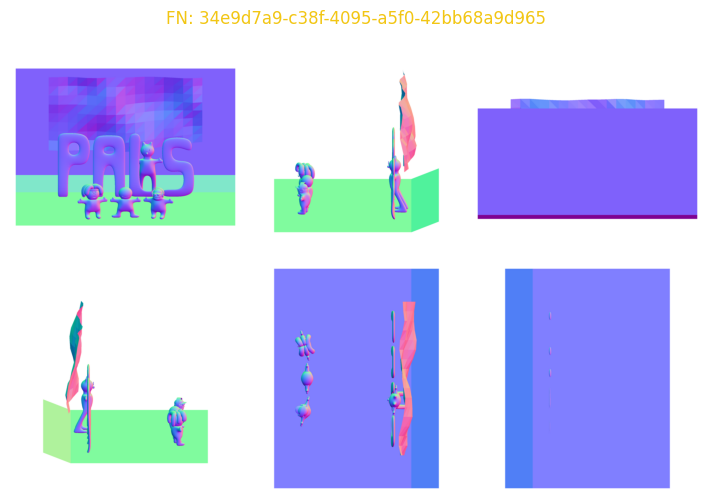

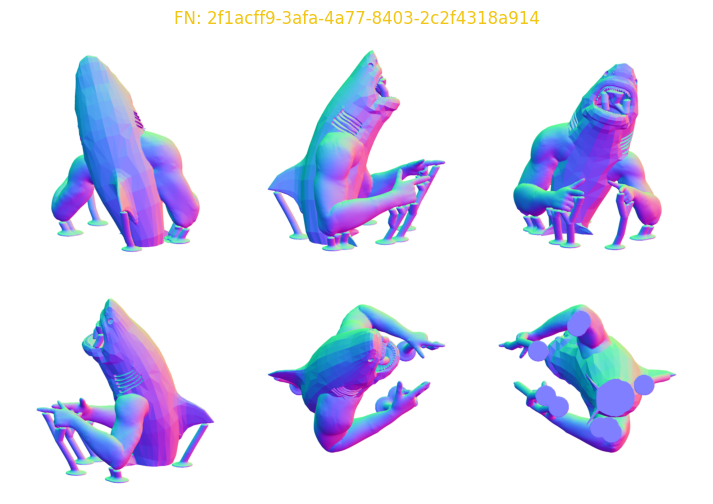

In [9]:
review = val_df[['item_id', 'lowpoly', 'simple', 'noisy', 'artifacts']].copy()
review['probability'] = probabilities[best_name].to_numpy()
review['prediction'] = best_prediction.astype(int)
for label, mask in [
    ('lowpoly + simple', review.lowpoly.eq(1) & review.simple.eq(1)),
    ('lowpoly + noisy', review.lowpoly.eq(1) & review.noisy.eq(1)),
    ('lowpoly + artifacts', review.lowpoly.eq(1) & review.artifacts.eq(1)),
    ('lowpoly without these', review.lowpoly.eq(1) & review[['simple','noisy','artifacts']].sum(axis=1).eq(0))]:
    group = review[mask]
    print(label, '| объектов:', len(group), '| FN:', int(group.prediction.eq(0).sum()))

false_pos = review.query('lowpoly == 0 and prediction == 1').sort_values('probability', ascending=False)
false_neg = review.query('lowpoly == 1 and prediction == 0').sort_values('probability')
focus = ['faces_count', 'dihedral_p90', 'pca_curvature_p90',
         'edge_p90_relative', 'triangle_aspect_p90']
for title, frame in [('FP', false_pos), ('FN', false_neg)]:
    print(title, '| всего:', len(frame))
    show = frame.head(4).join(features[focus], on='item_id')
    display(show[['item_id','lowpoly','simple','noisy','artifacts','probability'] + focus].round(4))
    for item_id in show.item_id:
        with Image.open(train_dir / f'{item_id}.png') as image:
            plt.figure(figsize=(12, 6))
            plt.imshow(image.convert('RGB'))
            plt.title(f'{title}: {item_id}', color='#F2C614')
            plt.axis('off'); plt.show()

## 9. Выводы

In [10]:
gain = best_row.F1 - old_fusion['F1']
print('Превзошли 0.5464:', bool(gain > 0), '| разница F1:', round(gain, 4))
print('Лучший вариант:', best_name)
print('Новые признаки в топ-20 importance:', [x for x in importance.head(20).index if x in NEW_FEATURES])
e3_f1 = results_table.set_index('Experiment').loc['E3_combined', 'F1']
for name in ('A_no_curvature', 'A_no_dihedral'):
    without_f1 = results_table.set_index('Experiment').loc[name, 'F1']
    print(name, '| F1:', round(without_f1, 4), '| разница с E3:', round(without_f1 - e3_f1, 4))
for family, names in [('Двугранные углы', [x for x in NEW_FEATURES if x.startswith('dihedral')]),
                      ('Кривизна', [x for x in NEW_FEATURES if x.startswith(('curvature','pca_curvature'))])]:
    print(family, '| в топ-20:', [x for x in importance.head(20).index if x in names])
print('FP и FN показаны выше. Типы объектов по рендерам требуют ручной проверки.')
print('DINOv2 пока не запускали для lowpoly: сначала сравниваем геометрию.')
print('E5 decimation отложен: в данных есть меши до 26 млн граней. Для него нужен отдельный ограниченный эксперимент.')
print('Validation использовалась для остановки, подбора порога и выбора модели. Internal test не использован.')

Превзошли 0.5464: True | разница F1: 0.052
Лучший вариант: A_no_curvature
Новые признаки в топ-20 importance: ['triangle_max_angle_p90', 'faces_per_bbox_volume', 'area_p95_relative', 'area_p90_relative', 'dihedral_edge_weighted_p90', 'dihedral_p50', 'area_tiny_share', 'triangle_thin_share', 'edge_p10_relative', 'dihedral_p75', 'edge_long_share', 'dihedral_over_60_share']
A_no_curvature | F1: 0.5984 | разница с E3: 0.0105
A_no_dihedral | F1: 0.5617 | разница с E3: -0.0262
Двугранные углы | в топ-20: ['dihedral_edge_weighted_p90', 'dihedral_p50', 'dihedral_p75', 'dihedral_over_60_share']
Кривизна | в топ-20: []
FP и FN показаны выше. Типы объектов по рендерам требуют ручной проверки.
DINOv2 пока не запускали для lowpoly: сначала сравниваем геометрию.
E5 decimation отложен: в данных есть меши до 26 млн граней. Для него нужен отдельный ограниченный эксперимент.
Validation использовалась для остановки, подбора порога и выбора модели. Internal test не использован.
